# **CHECKPOINT 2 **
## ** Data Preprocessing **

### **(a)**

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

filename = "college_major_career_outcomes_2026.csv.gz"

df = pd.read_csv(filename)

og_df = df.copy() # saving an un-altered copy

print("----------Data Info----------")
df.info()

print("----------Data Shape----------")
print(df.shape)
print('The dataset has ', df.shape[0], ' rows and ', df.shape[1], ' columns.')


----------Data Info----------
<class 'pandas.DataFrame'>
RangeIndex: 227980 entries, 0 to 227979
Data columns (total 72 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   program_id                            227980 non-null  str    
 1   unitid                                220960 non-null  float64
 2   opeid6                                227980 non-null  int64  
 3   institution_name                      227980 non-null  str    
 4   institution_control                   227980 non-null  str    
 5   is_main_campus                        227980 non-null  int64  
 6   institution_city                      216684 non-null  str    
 7   institution_state                     216684 non-null  str    
 8   institution_region                    216684 non-null  str    
 9   institution_latitude                  216684 non-null  float64
 10  institution_longitude                 216684 non-

### **(b)**

In [15]:
for col in ['unitid', 'opeid6', 'cip_family_code', 'cip_code_4digit']:
    df[col] = df[col].astype(str)

for col in ['is_main_campus', 'institution_is_hbcu', 'outcomes_shared_across_campuses']:
    df[col] = df[col].astype('boolean')

categorical_cols = ["institution_control", "institution_region", "institution_state",
            "credential_name", "distance_education", "cip_family_title",
            "earnings_trajectory_category", "occupation_typical_entry_education",
            "earnings_1yr_status", "earnings_4yr_status",
            "earnings_5yr_status", "debt_status", 'cip_title']

for col in categorical_cols:
    df[col] = df[col].astype('category')


count_cols = ["awards_year1", "awards_year2", "earnings_cohort_size_1yr",
              "earnings_cohort_size_4yr", "earnings_cohort_size_5yr",
              "not_working_count_5yr", "count_above_hs_threshold_5yr",
              "count_working_in_state_5yr", "debt_borrower_count",
              "linked_occupations_count", "linked_occupations_in_bls",
              "linked_occupations_in_onet", "occupations_using_ai_software"]

for col in count_cols:
    df[col] = df[col].astype("Int64")

for col in ["institution_name", "institution_city", "cip_title", "largest_linked_occupation"]:
    df[col] = df[col].str.strip()    


### **(c)**

In [16]:
print("----------Checking Program IDs----------")
num_prog = df['program_id'].nunique() 

if num_prog == len(df):
    print(f"Each row is a unique program ID, ({num_prog} total)")

else:
    print(f"There are duplicate program IDs, ({num_prog} total)")


----------Checking Program IDs----------
Each row is a unique program ID, (227980 total)


# **CHECKPOINT 2 **
## ** Basic data exploration and summary statistics **

THE THREE QUESTIONS: 


Does earnings growth increase at the same rate for all programs/career fields?

Does the number of degrees awarded (year1 and year2 combined) correlate to higher earnings?

Do schools with higher average SAT scores charge more for tuition?

## First Hypothesis

- HO: The mean earnings growth is equal across all programs/career fields.

- HA: At least one program/career field has a different mean earnings growth.

C:\Users\jason\AppData\Local\Temp\ipykernel_3100\4087515418.py:7: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


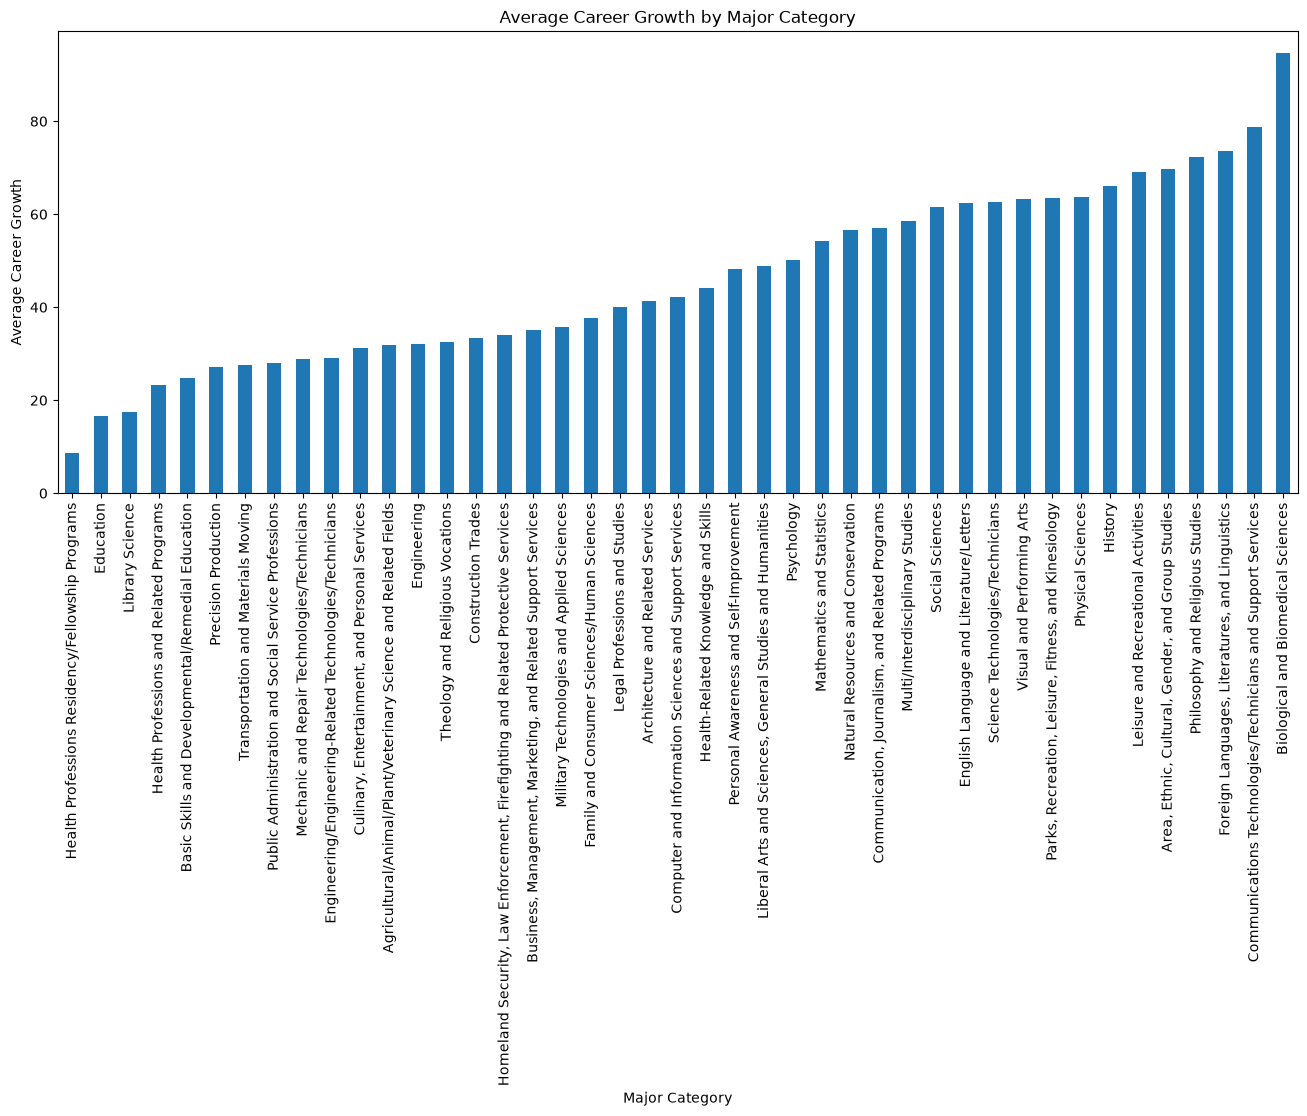

In [17]:
df.dropna(subset=["earnings_growth_pct_1yr_to_5yr"]).groupby("cip_family_title")["earnings_growth_pct_1yr_to_5yr"].mean().sort_values().plot(kind="bar", figsize=(16, 6))

plt.xlabel("Major Category")
plt.ylabel("Average Career Growth")
plt.title("Average Career Growth by Major Category")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Conducting ANOVA test

In [32]:
programs = df.dropna(subset="earnings_growth_pct_1yr_to_5yr").groupby("cip_family_title")["earnings_growth_pct_1yr_to_5yr"]

groups = []
for name,group in programs:
  # if len(group) >=2 :
    groups.append(group)



f, p = stats.f_oneway(*groups)


print("F-statistic:", f)
print("P-value:", p)



F-statistic: 264.21140179707027
P-value: 0.0


P-value is less than 0.05 so we reject the Null Hypothesis.
Possible errors in data, most of the data in the dataset for earnings is restricted, so it is probably missing at random and was just dropped. 

## Second Hypothesis

- HO: The number of degrees awarded (year1 and year2 combined) does not correlate to higher earnings.

- HA: The number of degrees awarded (year1 and year2 combined) correlates to higher earnings.

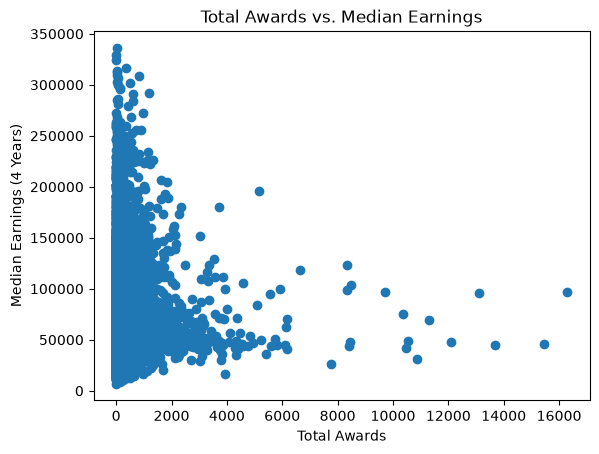

In [44]:
df["awards_year1"] = df["awards_year1"].fillna(0)
df["awards_year2"] = df["awards_year2"].fillna(0)

df["total_awards"] = df["awards_year1"] + df["awards_year2"]

earnings = df[["total_awards", "median_earnings_4yr_usd"]].dropna()

plt.scatter(earnings["total_awards"], earnings["median_earnings_4yr_usd"])
plt.xlabel("Total Awards")
plt.ylabel("Median Earnings (4 Years)")
plt.title("Total Awards vs. Median Earnings")
plt.show()


In [45]:
r, p = stats.pearsonr(earnings["total_awards"], earnings["median_earnings_4yr_usd"])

print("Pearson r:", r)
print("P-value:", p)

Pearson r: 0.05755547977231665
P-value: 7.725028805500921e-44


We reject the null hypothesis because the p-value is less than 0.05. The associaltion between total awards from year 1 and year 2 is very small though. 

A possible error in our data is that many rows did not have an entry for some awards, which I assumed to just be zero. Another thing is earnings is restricted, so it is probably missing at random and was just dropped like before

## Third Hypothesis

- HO: Schools with higher average SAT scores do not charge more for tuition

- HA: Schools with higher average SAT scores charge more for tuition

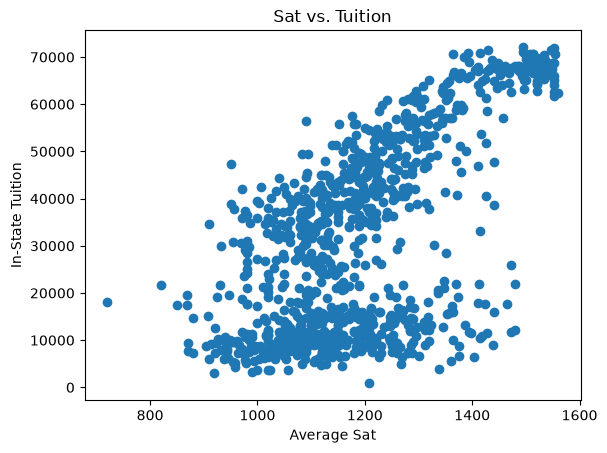

In [59]:
sat = df[["institution_name", "institution_avg_sat", "institution_tuition_in_state_usd"]]

sat = sat.dropna()
sat = sat.drop_duplicates()
# sat[sat["institution_name"].duplicated(keep=False)]

plt.scatter(sat["institution_avg_sat"], sat["institution_tuition_in_state_usd"])
plt.xlabel("Average Sat")
plt.ylabel("In-State Tuition")
plt.title("Sat vs. Tuition")
plt.show()


In [60]:
r, p = stats.pearsonr(sat["institution_avg_sat"], sat["institution_tuition_in_state_usd"])

print("Pearson r:", r)
print("P-value:", p)

Pearson r: 0.6246319065555453
P-value: 1.5801422142645237e-112


We reject the null hypothesis because the p-value is less than 0.05. The associaltion average sat and tuition is quite high.

A possible error in our data is the dataset is on programs and not on schools, so there may be somethings that are not representative of the population 